Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [1]:
# =========================
# SETUP — FIGURES AFTER FIX
# =========================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



optuna_results_dir      = os.path.join(str(project_path("results/optuna")))
sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))
figures_dir             = os.path.join(str(project_path("results/figures_revised")))

os.makedirs(figures_dir, exist_ok=True)


# =========================
# WSPÓLNA PALETA — 7 MODELI
# =========================

model_colors = {
    "popularność":                     "tab:gray",
    "BPR":                             "black",
    "stała (γ)":                       "tab:purple",
    "liniowa":                         "tab:blue",
    "logarytmiczna":                   "tab:orange",
    "logarytmiczna z saturacją":       "tab:red",
    "logarytmiczna z przesunięciem β": "tab:green",
}

# mapowanie z nazw technicznych na etykiety
function_labels = {
    "popular":         "popularność",
    "bpr":             "BPR",
    "constant":        "stała (γ)",
    "linear":          "liniowa",
    "log":             "logarytmiczna",
    "log_saturation":  "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

# kolory dostępne również pod kluczem technicznym
function_colors = {
    fn: model_colors[label]
    for fn, label in function_labels.items()
}

model_order = [
    "popular",
    "bpr",
    "constant",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]


# =========================
# WCZYTANIE
# =========================

best_configs = pd.read_csv(
    os.path.join(optuna_results_dir, "best_als_configs.csv")
)

gamma_df = pd.read_csv(
    os.path.join(sensitivity_results_dir, "sensitivity_gamma_constant.csv")
).sort_values("gamma").reset_index(drop=True)

print("Katalog wykresów:", figures_dir)
print("gamma_df:", gamma_df.shape)

Katalog wykresów: D:\Studiowe\Licencjat\modele\figures_after_fix
gamma_df: (40, 10)


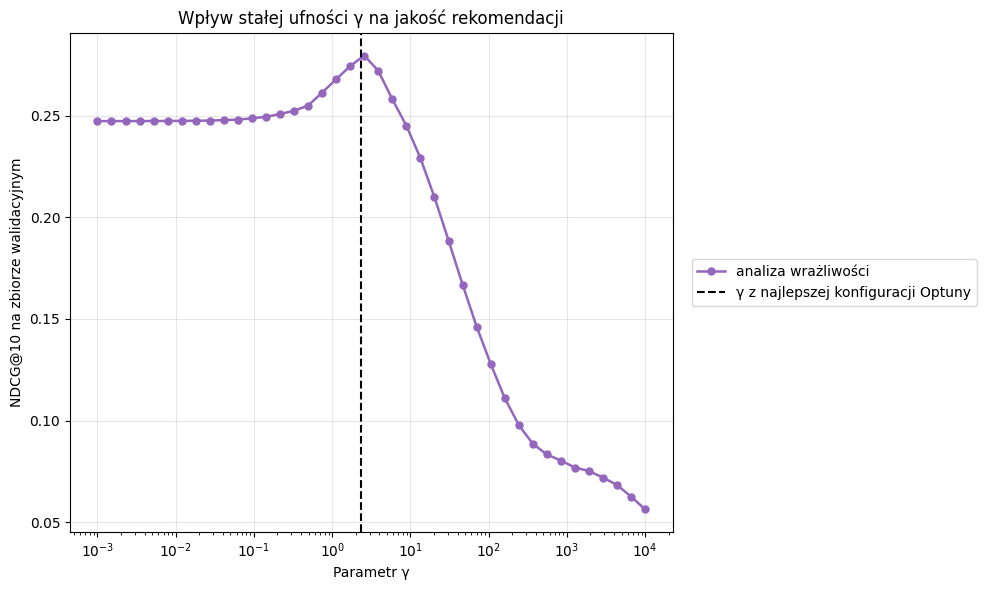

Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\wrazliwosc_constant_ndcg_vs_gamma.png


In [2]:
# =========================
# WRAŻLIWOŚĆ NA GAMMA — NDCG vs GAMMA
# =========================

constant_best = best_configs[
    best_configs["function"] == "constant"
].iloc[0]

best_gamma = float(constant_best["gamma"])

plt.figure(figsize=(10, 6))

plt.plot(
    gamma_df["gamma"],
    gamma_df["validation_ndcg@10"],
    marker="o",
    linewidth=1.8,
    markersize=5,
    color=function_colors["constant"],
    label="analiza wrażliwości",
)

plt.axvline(
    best_gamma,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="γ z najlepszej konfiguracji Optuny",
)

plt.xscale("log")
plt.xlabel("Parametr γ")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ stałej ufności γ na jakość rekomendacji")

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_constant_ndcg_vs_gamma.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

In [3]:
# =========================
# HELPER: ZAPIS WYKRESÓW
# =========================

def save_figure(filename):
    path = os.path.join(figures_dir, filename)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Zapisano: {path}")
    return path


# =========================
# PARSOWANIE "mean ± std"
# =========================

def parse_mean_std(value):
    """Rozbija string typu '0.2703 ± 0.0006' na (mean, std)."""
    if pd.isna(value):
        return np.nan, np.nan

    text = str(value).replace("±", "|").replace("+/-", "|")
    parts = [p.strip() for p in text.split("|")]

    mean = float(parts[0])
    std = float(parts[1]) if len(parts) > 1 else np.nan

    return mean, std


# =========================
# WYNIKI ALS + POPULAR
# =========================

final_results_dir = os.path.join(str(project_path("results/final")))

test_summary = pd.read_csv(
    os.path.join(final_results_dir, "test_summary.csv")
)

results = test_summary[
    ["function", "ndcg@10_mean", "ndcg@10_std"]
].copy()


# =========================
# WYNIKI BPR
# =========================

bpr_path = os.path.join(
    str(project_path("results/bpr")), "final",
    "bpr_test_metrics_summary_pretty.csv"
)

bpr_raw = pd.read_csv(bpr_path)

bpr_mean, bpr_std = parse_mean_std(bpr_raw["ndcg@10"].iloc[0])

bpr_row = pd.DataFrame([{
    "function": "bpr",
    "ndcg@10_mean": bpr_mean,
    "ndcg@10_std": bpr_std,
}])

results = pd.concat([results, bpr_row], ignore_index=True)


# =========================
# ETYKIETY I KOLEJNOŚĆ
# =========================

results["Model"] = results["function"]
results["label"] = results["function"].map(function_labels)

results["order"] = results["function"].map(
    {name: i for i, name in enumerate(model_order)}
)

results = results.sort_values("order").reset_index(drop=True)

display(
    results[["function", "label", "ndcg@10_mean", "ndcg@10_std"]]
)

print(f"\nLiczba modeli: {len(results)}")

,function,label,ndcg@10_mean,ndcg@10_std
0,popular,popularność,0.185480,NaN
1,bpr,BPR,0.270300,0.000600
2,constant,stała (γ),0.356542,0.000462
3,linear,liniowa,0.329930,0.000523
4,log,logarytmiczna,0.335613,0.000295
5,log_saturation,logarytmiczna z saturacją,0.335418,0.000484
6,log_inside_beta,logarytmiczna z przesunięciem β,0.351690,0.000352



Liczba modeli: 7


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_ndcg_all_models_horizontal.png


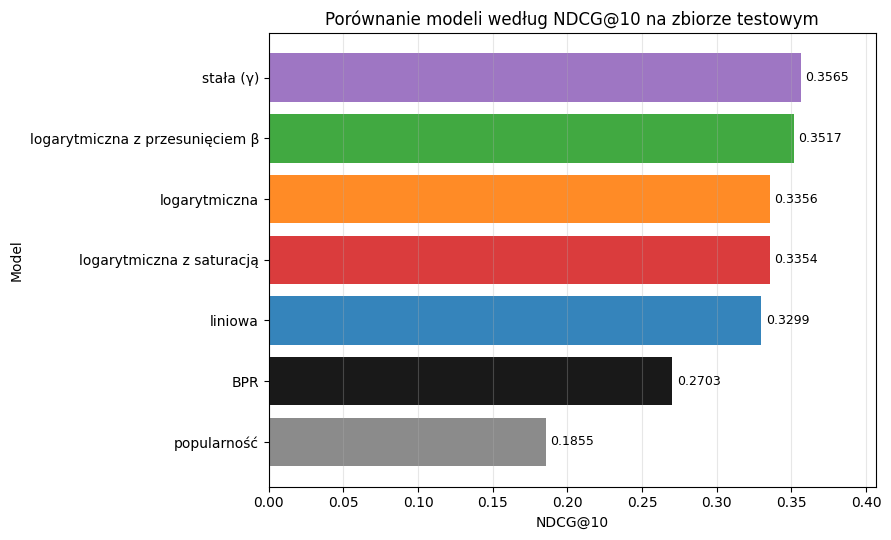

In [4]:
# ============================================================
# NDCG@10 — wszystkie modele — słupki poziome
# ============================================================

plot_df = results.copy().sort_values("ndcg@10_mean", ascending=True)

models = plot_df["Model"].tolist()
values = plot_df["ndcg@10_mean"].tolist()
y = np.arange(len(models))

plt.figure(figsize=(9, 5.5))

plt.barh(
    y,
    values,
    color=[function_colors.get(m, "gray") for m in models],
    alpha=0.9,
)

plt.yticks(y, [function_labels.get(m, m) for m in models])
plt.xlabel("NDCG@10")
plt.ylabel("Model")
plt.title("Porównanie modeli według NDCG@10 na zbiorze testowym")
plt.grid(axis="x", alpha=0.3)

plt.xlim(0, max(values) * 1.14)

for i, value in enumerate(values):
    plt.text(
        value + max(values) * 0.008,
        i,
        f"{value:.4f}",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
save_figure("test_ndcg_all_models_horizontal.png")
plt.show()

In [5]:
# =========================
# PEŁNA TABELA WYNIKÓW — WSZYSTKIE METRYKI
# =========================

metrics = [
    "precision@10",
    "recall@10",
    "ndcg@10",
    "coverage@10",
    "delta_gap@10",
    "diversity@10",
]

# --- ALS + Popular ---
cols = ["function"]
for m in metrics:
    cols += [f"{m}_mean", f"{m}_std"]

results = test_summary[cols].copy()


# --- BPR ---
bpr_row = {"function": "bpr"}

for m in metrics:
    mean, std = parse_mean_std(bpr_raw[m].iloc[0])
    bpr_row[f"{m}_mean"] = mean
    bpr_row[f"{m}_std"] = std

results = pd.concat(
    [results, pd.DataFrame([bpr_row])],
    ignore_index=True
)


# --- etykiety i kolejność ---
results["Model"] = results["function"]
results["label"] = results["function"].map(function_labels)

results["order"] = results["function"].map(
    {name: i for i, name in enumerate(model_order)}
)

results = results.sort_values("order").reset_index(drop=True)

display(
    results[["label"] + [f"{m}_mean" for m in metrics]]
)

,label,precision@10_mean,recall@10_mean,ndcg@10_mean,coverage@10_mean,delta_gap@10_mean,diversity@10_mean
0,popularność,0.096519,0.178252,0.185480,0.008698,1.423258,NaN
1,BPR,0.132900,0.261400,0.270300,0.303900,-0.078900,0.549900
2,stała (γ),0.197810,0.336984,0.356542,0.137443,0.420977,0.761570
3,liniowa,0.184100,0.264170,0.329930,0.117786,-0.211241,0.785433
4,logarytmiczna,0.180967,0.301856,0.335613,0.076169,0.543323,0.596301
5,logarytmiczna z saturacją,0.180868,0.301907,0.335418,0.076104,0.544328,0.594833
6,logarytmiczna z przesunięciem β,0.195639,0.333795,0.351690,0.131333,0.419129,0.731420


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_precision_vs_recall_all_models.png


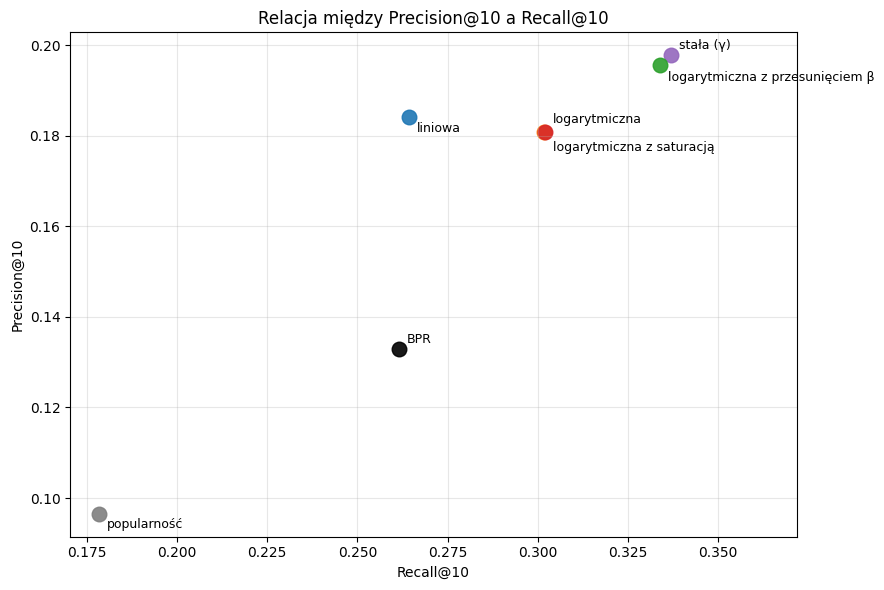

In [6]:
# ============================================================
# Precision@10 vs Recall@10 — wszystkie modele
# ============================================================

plot_df = results.copy()

label_offsets = {
    "popular":         (6, -8),
    "bpr":             (6, 7),
    "constant":        (6, 7),
    "linear":          (6, -8),
    "log":             (6, 9),
    "log_saturation":  (6, -11),
    "log_inside_beta": (6, -9),
}

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["recall@10_mean"]
    y_val = row["precision@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=function_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        function_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Recall@10")
plt.ylabel("Precision@10")
plt.title("Relacja między Precision@10 a Recall@10")
plt.grid(alpha=0.3)

# zapas z prawej, żeby etykiety nie wychodziły poza obszar
x_min = plot_df["recall@10_mean"].min()
x_max = plot_df["recall@10_mean"].max()
x_span = x_max - x_min
plt.xlim(x_min - 0.05 * x_span, x_max + 0.22 * x_span)

plt.tight_layout()

save_figure("test_precision_vs_recall_all_models.png")
plt.show()

Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_ndcg_vs_coverage_all_models.png


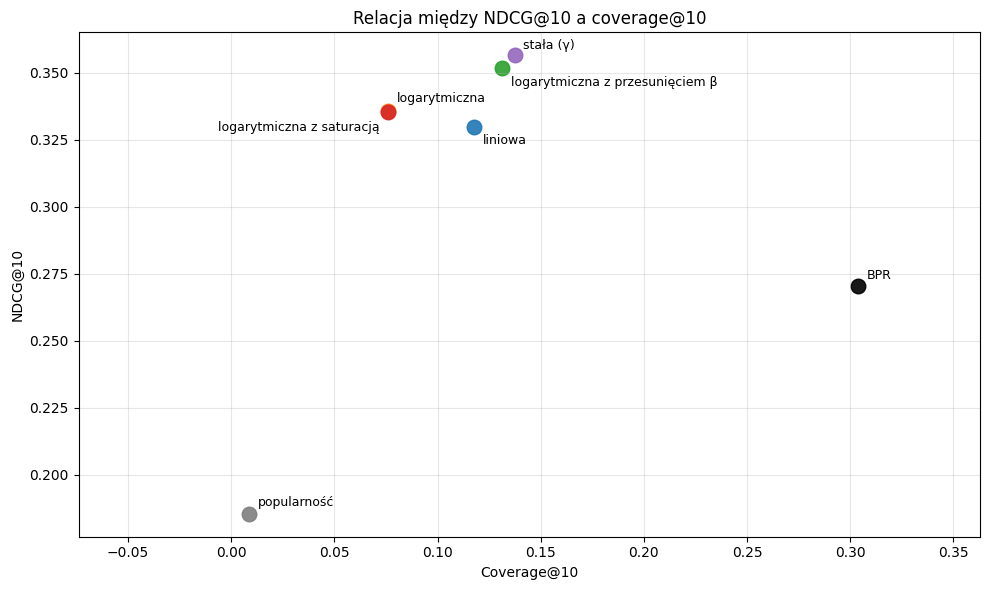

In [8]:
# ============================================================
# NDCG@10 vs Coverage@10 — wszystkie modele
# ============================================================

plot_df = results.copy()

label_offsets = {
    "popular":         (6, 8),
    "bpr":             (6, 8),
    "constant":        (6, 7),
    "linear":          (6, -10),
    "log":             (6, 9),
    "log_saturation":  (-6, -11),   # etykieta w lewo — kolizja z punktem "liniowa"
    "log_inside_beta": (6, -10),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["coverage@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=function_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        function_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="right" if dx < 0 else "left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Coverage@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a coverage@10")
plt.grid(alpha=0.3)

# marginesy pod etykiety: szerszy z lewej, bo "log. z saturacją" idzie w lewo
x_min = plot_df["coverage@10_mean"].min()
x_max = plot_df["coverage@10_mean"].max()
x_span = x_max - x_min
plt.xlim(x_min - 0.28 * x_span, x_max + 0.20 * x_span)

plt.tight_layout()

save_figure("test_ndcg_vs_coverage_all_models.png")
plt.show()

Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_ndcg_vs_diversity_als_only.png


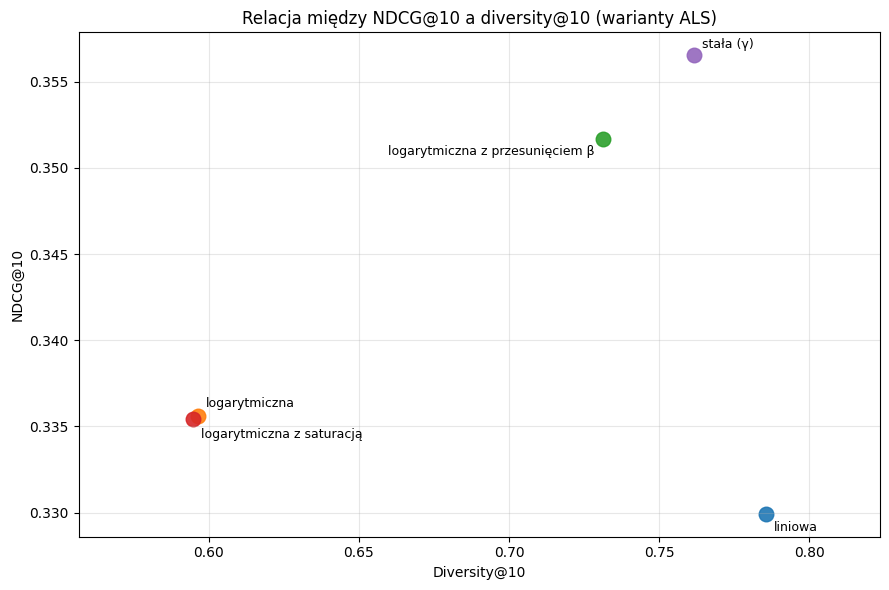

In [9]:
# ============================================================
# NDCG@10 vs Diversity@10 — tylko warianty ALS
# Porównanie ograniczone do jednej rodziny modeli:
# przestrzenie latentne różnych algorytmów nie są porównywalne.
# ============================================================

als_functions = ["constant", "linear", "log", "log_saturation", "log_inside_beta"]

plot_df = results[
    results["function"].isin(als_functions)
    & (~results["diversity@10_mean"].isna())
].copy()

label_offsets = {
    "constant":        (6, 8),
    "linear":          (6, -10),
    "log":             (6, 9),
    "log_saturation":  (6, -11),
    "log_inside_beta": (-6, -9),
}

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["diversity@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=function_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        function_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="right" if dx < 0 else "left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Diversity@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a diversity@10 (warianty ALS)")
plt.grid(alpha=0.3)

x_min = plot_df["diversity@10_mean"].min()
x_max = plot_df["diversity@10_mean"].max()
x_span = x_max - x_min
plt.xlim(x_min - 0.20 * x_span, x_max + 0.20 * x_span)

plt.tight_layout()

save_figure("test_ndcg_vs_diversity_als_only.png")
plt.show()

## test innego diversity

In [10]:
# =========================
# ITEM-ITEM SIMILARITY Z WSPÓŁWYSTĘPOWANIA
# wspólna przestrzeń dla wszystkich modeli
# =========================

import os
import sys
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

data_dir = os.path.join(str(project_path("data/processed")))

interactions = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

interactions["user_id"] = interactions["user_id"].astype(str)
interactions["item_id"] = interactions["item_id"].astype(str)

test_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_test.csv")
)
test_df["user_id"] = test_df["user_id"].astype(str)
test_df["item_id"] = test_df["item_id"].astype(str)


# mapowanie na indeksy — niezależne od jakiegokolwiek modelu
cooc_items = sorted(interactions["item_id"].unique())
cooc_item2idx = {item: i for i, item in enumerate(cooc_items)}

cooc_users = sorted(interactions["user_id"].unique())
cooc_user2idx = {user: i for i, user in enumerate(cooc_users)}

rows = interactions["user_id"].map(cooc_user2idx).values
cols = interactions["item_id"].map(cooc_item2idx).values

# macierz BINARNA — playtime celowo ignorowany,
# metryka ma opisywać współwystępowanie, nie intensywność
R = csr_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, cols)),
    shape=(len(cooc_users), len(cooc_items))
)

# kolumny znormalizowane -> iloczyn skalarny = cosinus
R_norm = normalize(R, norm="l2", axis=0)

print(f"Macierz interakcji: {R.shape}, nnz={R.nnz}")
print(f"Pozycji w katalogu: {len(cooc_items)}")


def ild_cooccurrence(rec_item_ids, k=10):
    """
    Intra-List Distance na podobieństwie ze współwystępowania.
    rec_item_ids: lista ORYGINALNYCH item_id (stringi).
    """
    idxs = [
        cooc_item2idx[i] for i in rec_item_ids[:k]
        if i in cooc_item2idx
    ]

    if len(idxs) < 2:
        return np.nan

    sub = R_norm[:, idxs]
    sim = (sub.T @ sub).toarray()

    n = len(idxs)
    iu = np.triu_indices(n, k=1)

    return float(np.mean(1.0 - sim[iu]))


def mean_ild(recommendations, idx2item, k=10):
    """Średnie ILD po użytkownikach."""
    vals = []
    for _, rec_idxs in recommendations.items():
        orig = [idx2item[i] for i in rec_idxs]
        v = ild_cooccurrence(orig, k=k)
        if not np.isnan(v):
            vals.append(v)
    return float(np.mean(vals)), len(vals)

C:\Users\misie\AppData\Local\Temp\ipykernel_8392\63299706.py:18: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  interactions = pd.read_csv(


Macierz interakcji: (62944, 9198), nnz=4543733
Pozycji w katalogu: 9198


In [12]:
# =========================
# ILD DLA WSZYSTKICH MODELI FAKTORYZACYJNYCH
# UWAGA: nic nie jest zapisywane na dysk
# =========================

from steam_recommender.als import ALSPipeline
from steam_recommender.confidence import linear_signal, log_signal, log_saturated_signal, make_log_inside_beta_signal, make_constant_signal

from steam_recommender.bpr import BPRPipeline


def get_signal_fn(fn_name, beta=None, gamma=None):
    if fn_name == "linear":          return linear_signal
    if fn_name == "log":             return log_signal
    if fn_name == "log_saturation":  return log_saturated_signal
    if fn_name == "log_inside_beta": return make_log_inside_beta_signal(float(beta))
    if fn_name == "constant":        return make_constant_signal(float(gamma))
    raise ValueError(fn_name)


K = 10
ild_rows = []

als_functions = ["constant", "linear", "log", "log_saturation", "log_inside_beta"]


# --- warianty ALS ---
for fn_name in tqdm(als_functions, desc="ALS"):
    cfg = best_configs[best_configs["function"] == fn_name].iloc[0]

    beta = cfg["beta"] if not pd.isna(cfg["beta"]) else None
    gamma = cfg["gamma"] if not pd.isna(cfg["gamma"]) else None

    pipeline = ALSPipeline(
        factors=int(cfg["factors"]),
        iterations=int(cfg["iterations"]),
        alpha=float(cfg["alpha"]),
        regularization=float(cfg["regularization"]),
        random_state=0,
        signal_strength_fn=get_signal_fn(fn_name, beta, gamma),
        num_threads=8,
    )

    _, recommendations = pipeline.refit_full_and_test(
        train_df=interactions,
        test_df=test_df,
        K=K,
        return_per_user=False,
        verbose=False,
    )

    ild, n = mean_ild(recommendations, pipeline.idx2item, K)

    ild_rows.append({
        "function": fn_name,
        "label": function_labels[fn_name],
        "factors": int(cfg["factors"]),
        "ild_cooccurrence@10": ild,
        "n_users": n,
    })

    print(f"{fn_name:18s} factors={int(cfg['factors']):3d}  ILD={ild:.4f}")


# --- BPR ---
bpr = BPRPipeline(
    factors=96,
    iterations=150,
    learning_rate=0.0017602669790432763,
    regularization=0.0032374923658688454,
    random_state=0,
    num_threads=8,
)

_, bpr_recommendations = bpr.refit_full_and_test(
    train_df=interactions,
    test_df=test_df,
    K=K,
    return_per_user=False,
    verbose=False,
)

bpr_ild, bpr_n = mean_ild(bpr_recommendations, bpr.idx2item, K)

ild_rows.append({
    "function": "bpr",
    "label": function_labels["bpr"],
    "factors": 96,
    "ild_cooccurrence@10": bpr_ild,
    "n_users": bpr_n,
})

print(f"{'bpr':18s} factors= 96  ILD={bpr_ild:.4f}")


ild_df = pd.DataFrame(ild_rows)
display(ild_df)

Wykonano komórkę z definicją BPRPipeline
BPRPipeline dostępna: True


ALS:   0%|          | 0/5 [00:00<?, ?it/s]

d:\Anaconda\envs\recommender\Lib\site-packages\implicit\cpu\als.py:95: RuntimeWarning: Intel MKL BLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'MKL_NUM_THREADS=1' or by callng 'threadpoolctl.threadpool_limits(1, "blas")'. Having MKL use a threadpool can lead to severe performance issues
  check_blas_config()


  0%|          | 0/30 [00:00<?, ?it/s]

constant           factors= 48  ILD=0.6825


...

  0%|          | 0/30 [00:00<?, ?it/s]

log_saturation     factors= 24  ILD=0.6470


  0%|          | 0/30 [00:00<?, ?it/s]

log_inside_beta    factors= 48  ILD=0.6841


NameError: name 'BayesianPersonalizedRanking' is not defined

In [13]:
from implicit.bpr import BayesianPersonalizedRanking
print("dostępne:", "BayesianPersonalizedRanking" in globals())

dostępne: True


In [14]:
import sys
from implicit.bpr import BayesianPersonalizedRanking
from scipy.sparse import csr_matrix
import numpy as np

# wstrzyknięcie zależności do namespace, w którym zdefiniowano klasę
BPRPipeline.__init__.__globals__.update({
    "BayesianPersonalizedRanking": BayesianPersonalizedRanking,
    "csr_matrix": csr_matrix,
    "np": np,
})

print("OK")

OK


In [16]:
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.metrics import precision_at_k, recall_at_k, ndcg_at_k, coverage_at_k, delta_gap, diversity_at_k
# --- BPR ---
bpr = BPRPipeline(
    factors=96,
    iterations=150,
    learning_rate=0.0017602669790432763,
    regularization=0.0032374923658688454,
    random_state=0,
    num_threads=8,
)

_, bpr_recommendations = bpr.refit_full_and_test(
    train_df=interactions,
    test_df=test_df,
    K=K,
    return_per_user=False,
    verbose=False,
)

bpr_ild, bpr_n = mean_ild(bpr_recommendations, bpr.idx2item, K)

ild_rows.append({
    "function": "bpr",
    "label": function_labels["bpr"],
    "factors": 96,
    "ild_cooccurrence@10": bpr_ild,
    "n_users": bpr_n,
})

print(f"{'bpr':18s} factors= 96  ILD={bpr_ild:.4f}")


ild_df = pd.DataFrame(ild_rows)
display(ild_df)

  0%|          | 0/150 [00:00<?, ?it/s]

bpr                factors= 96  ILD=0.7363


,function,label,factors,ild_cooccurrence@10,n_users
0,constant,stała (γ),48,0.682547,62944
1,linear,liniowa,80,0.752758,62944
2,log,logarytmiczna,24,0.646942,62944
3,log_saturation,logarytmiczna z saturacją,24,0.647033,62944
4,log_inside_beta,logarytmiczna z przesunięciem β,48,0.684076,62944
5,bpr,BPR,96,0.736297,62944


## znowu wykresy

Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_ndcg_vs_ild_cooccurrence.png


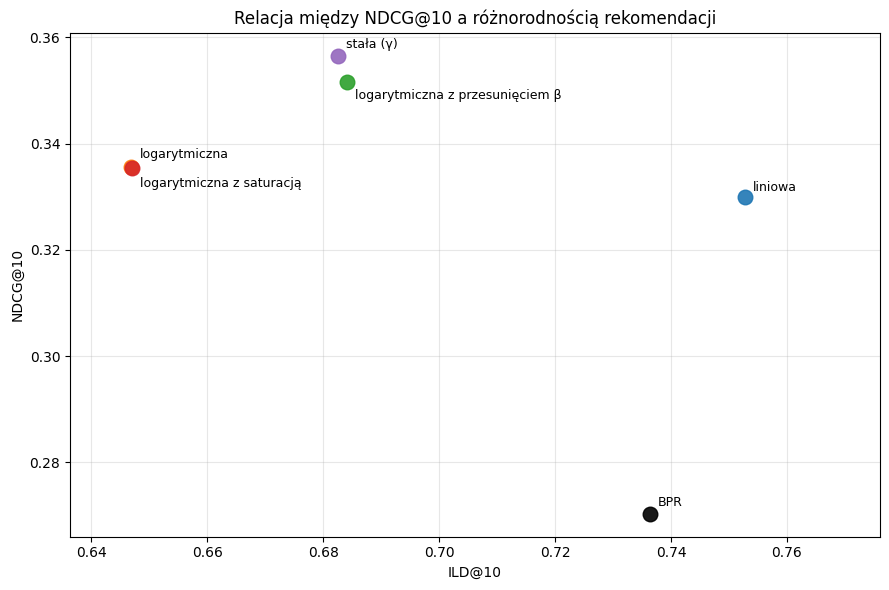

In [18]:
# ============================================================
# NDCG@10 vs ILD@10 (współwystępowanie) — modele faktoryzacyjne
# ============================================================

plot_df = ild_df.merge(
    results[["function", "ndcg@10_mean"]],
    on="function",
    how="left",
)

label_offsets = {
    "bpr":             (6, 8),
    "constant":        (6, 8),
    "linear":          (6, 7),
    "log":             (6, 9),
    "log_saturation":  (6, -11),
    "log_inside_beta": (6, -10),
}

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    model = row["function"]
    x_val = row["ild_cooccurrence@10"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=function_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        function_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="right" if dx < 0 else "left",
        va="center",
        fontsize=9,
    )

plt.xlabel("ILD@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a różnorodnością rekomendacji")
plt.grid(alpha=0.3)

x_min = plot_df["ild_cooccurrence@10"].min()
x_max = plot_df["ild_cooccurrence@10"].max()
x_span = x_max - x_min
plt.xlim(x_min - 0.10 * x_span, x_max + 0.22 * x_span)

plt.tight_layout()

save_figure("test_ndcg_vs_ild_cooccurrence.png")
plt.show()

Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\test_ndcg_vs_delta_gap_without_popularity.png


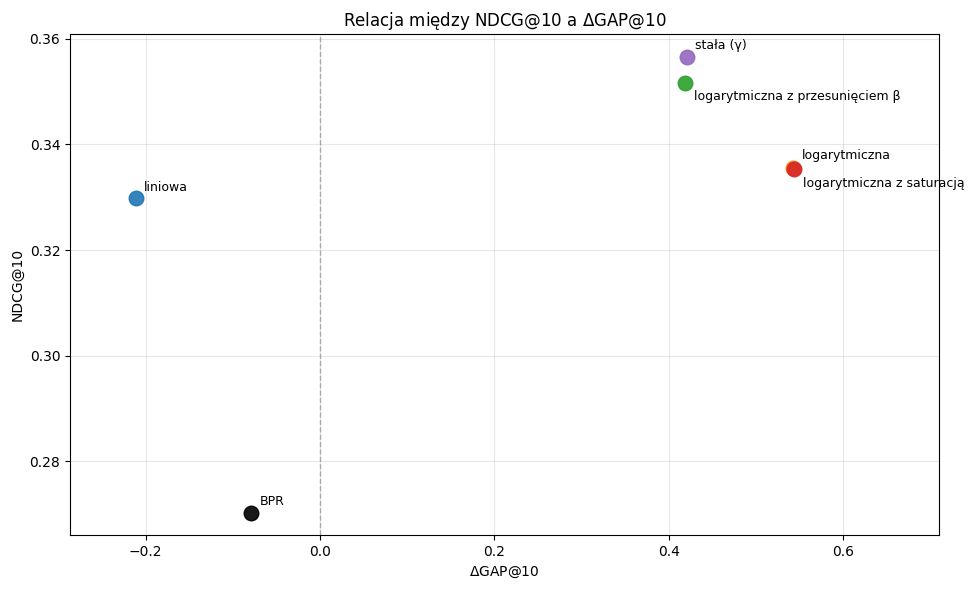

In [20]:
# ============================================================
# NDCG@10 vs ΔGAP@10 — bez baseline'u popularnościowego
# (popularność ma ΔGAP = 1.42 i zdominowałaby skalę wykresu)
# ============================================================

plot_df = results[results["function"] != "popular"].copy()

label_offsets = {
    "bpr":             (6, 8),
    "constant":        (6, 8),
    "linear":          (6, 7),
    "log":             (6, 9),
    "log_saturation":  (6, -11),
    "log_inside_beta": (6, -10),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    model = row["function"]
    x_val = row["delta_gap@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=function_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        function_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="right" if dx < 0 else "left",
        va="center",
        fontsize=9,
    )

plt.axvline(0, linestyle="--", linewidth=1, color="gray", alpha=0.6)

plt.xlabel(r"$\Delta$GAP@10")
plt.ylabel("NDCG@10")
plt.title(r"Relacja między NDCG@10 a $\Delta$GAP@10")
plt.grid(alpha=0.3)

x_min = plot_df["delta_gap@10_mean"].min()
x_max = plot_df["delta_gap@10_mean"].max()
x_span = x_max - x_min
plt.xlim(x_min - 0.10 * x_span, x_max + 0.22 * x_span)

plt.tight_layout()

save_figure("test_ndcg_vs_delta_gap_without_popularity.png")
plt.show()

## stabilnosc BPR

In [21]:
# =========================
# STABILNOŚĆ BPR — 5 PODZIAŁÓW TRAIN/VAL
# =========================

from steam_recommender.splitting import random_user_split_train_val

split_seeds = [0, 1, 2, 3, 4]
K = 10

bpr_val_rows = []

for split_seed in tqdm(split_seeds, desc="podziały"):

    train_split_df, val_split_df = random_user_split_train_val(
        interactions,
        val_frac=0.1,
        seed=split_seed
    )

    bpr_split = BPRPipeline(
        factors=96,
        iterations=150,
        learning_rate=0.0017602669790432763,
        regularization=0.0032374923658688454,
        random_state=0,
        num_threads=8,
    )

    bpr_split.fit(train_split_df, val_split_df)

    all_items = set(bpr_split.item2idx.values())

    item_interaction_count = (
        bpr_split.train_df
        .groupby("item_id")
        .size()
        .to_dict()
    )

    res, _ = bpr_split.evaluate_on(
        bpr_split.val_df,
        all_items=all_items,
        item_interaction_count=item_interaction_count,
        K=K,
        return_per_user=False,
        verbose=False,
    )

    row = {"split_seed": split_seed}
    row.update(res)
    bpr_val_rows.append(row)

    print(
        f"seed={split_seed}  "
        f"NDCG={res[f'ndcg@{K}']:.4f}  "
        f"cov={res[f'coverage@{K}']:.4f}  "
        f"ΔGAP={res[f'delta_gap@{K}']:.4f}"
    )


bpr_val_df = pd.DataFrame(bpr_val_rows)
display(bpr_val_df)


# =========================
# AGREGACJA DO FORMATU val_summary
# =========================

bpr_val_summary = {"model": "BPR", "function": "bpr", "n_splits": len(split_seeds)}

for m in ["precision@10", "recall@10", "ndcg@10",
          "coverage@10", "delta_gap@10", "diversity@10"]:
    bpr_val_summary[f"{m}_mean"] = bpr_val_df[m].mean()
    bpr_val_summary[f"{m}_std"] = bpr_val_df[m].std(ddof=1)

bpr_val_summary_df = pd.DataFrame([bpr_val_summary])

display(bpr_val_summary_df)

podziały:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

seed=0  NDCG=0.2102  cov=0.2847  ΔGAP=-0.0837


  0%|          | 0/150 [00:00<?, ?it/s]

seed=1  NDCG=0.2110  cov=0.2831  ΔGAP=-0.0765


...

seed=3  NDCG=0.2115  cov=0.2818  ΔGAP=-0.0824


  0%|          | 0/150 [00:00<?, ?it/s]

seed=4  NDCG=0.2111  cov=0.2819  ΔGAP=-0.0795


,split_seed,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,0,0.099665,0.231183,0.210190,0.284736,-0.083721,0.537527,62944
1,1,0.100175,0.232824,0.211024,0.283105,-0.076479,0.540879,62944
2,2,0.098718,0.229562,0.208909,0.283679,-0.082646,0.538359,62944
3,3,0.100267,0.233314,0.211532,0.281800,-0.082419,0.540285,62944
4,4,0.100044,0.232879,0.211110,0.281909,-0.079528,0.541101,62944


,model,function,n_splits,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std
0,BPR,bpr,5,0.099774,0.000633,0.231952,0.001563,0.210553,0.00104,0.283046,0.001235,-0.080959,0.002946,0.53963,0.001596


# tabele

In [22]:
# =========================
# TABELE ZBIORCZE DO PRACY
# =========================

tables_dir = os.path.join(figures_dir, "tabele")
os.makedirs(tables_dir, exist_ok=True)


def save_table(df, filename):
    path = os.path.join(tables_dir, filename)
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Zapisano: {path}")
    return path


# =========================
# TABELA 1 — HIPERPARAMETRY
# =========================

hp = best_configs.copy()
hp["label"] = hp["function"].map(function_labels)

hp_rows = []

for _, r in hp.iterrows():
    hp_rows.append({
        "Model": r["label"],
        "Liczba czynników": int(r["factors"]),
        "Iteracje": int(r["iterations"]),
        "α": f"{r['alpha']:.3e}" if not pd.isna(r["alpha"]) else "—",
        "β": f"{r['beta']:.2f}" if not pd.isna(r["beta"]) else "—",
        "γ": f"{r['gamma']:.4f}" if not pd.isna(r["gamma"]) else "—",
        "Regularyzacja": f"{r['regularization']:.4e}",
        "Współczynnik uczenia": "—",
        "NDCG@10 (walidacja)": f"{r['validation_ndcg']:.4f}",
        "Liczba prób": int(r["n_trials"]),
    })

# --- BPR ---
hp_rows.append({
    "Model": "BPR",
    "Liczba czynników": 96,
    "Iteracje": 150,
    "α": "—",
    "β": "—",
    "γ": "—",
    "Regularyzacja": f"{0.0032374923658688454:.4e}",
    "Współczynnik uczenia": f"{0.0017602669790432763:.4e}",
    "NDCG@10 (walidacja)": "0.2118",
    "Liczba prób": None,   # <- podaj
})

hyperparams_table = pd.DataFrame(hp_rows)

order_map = {function_labels[k]: i for i, k in enumerate(model_order)}
hyperparams_table["_o"] = hyperparams_table["Model"].map(order_map)
hyperparams_table = (
    hyperparams_table.sort_values("_o").drop(columns="_o").reset_index(drop=True)
)

display(hyperparams_table)
save_table(hyperparams_table, "tabela_hiperparametry.csv")

,Model,Liczba czynników,Iteracje,α,β,γ,Regularyzacja,Współczynnik uczenia,NDCG@10 (walidacja),Liczba prób
0,BPR,96,150,—,—,—,3.2375e-03,1.7603e-03,0.2118,NaN
1,stała (γ),48,30,1.000e+00,—,2.3642,5.7607e-02,—,0.2801,150.0
2,liniowa,80,30,9.948e-07,—,—,3.5879e-03,—,0.2489,150.0
3,logarytmiczna,24,30,5.714e-04,—,—,1.3092e-01,—,0.2613,150.0
4,logarytmiczna z saturacją,24,30,2.439e-02,—,—,1.6971e-01,—,0.2614,150.0
5,logarytmiczna z przesunięciem β,48,30,3.892e-01,108.28,—,1.0565e-02,—,0.2753,150.0


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\tabele\tabela_hiperparametry.csv


'D:\\Studiowe\\Licencjat\\modele\\figures_after_fix\\tabele\\tabela_hiperparametry.csv'

In [23]:
# =========================
# TABELA 2 — WALIDACJA (5 podziałów losowych)
# =========================

val_summary = pd.read_csv(
    os.path.join(str(project_path("results/validation")), "validation_stability_summary.csv")
)

metric_names = {
    "precision@10": "Precision@10",
    "recall@10":    "Recall@10",
    "ndcg@10":      "NDCG@10",
    "coverage@10":  "Coverage@10",
    "delta_gap@10": "ΔGAP@10",
}


def build_summary_table(df, source_label):
    rows = []
    for _, r in df.iterrows():
        row = {"Model": function_labels.get(r["function"], r["function"])}
        for key, name in metric_names.items():
            mean, std = r[f"{key}_mean"], r[f"{key}_std"]
            row[name] = "—" if pd.isna(mean) else (
                f"{mean:.4f}" if pd.isna(std) else f"{mean:.4f} ± {std:.4f}"
            )
        rows.append(row)

    out = pd.DataFrame(rows)
    out["_o"] = out["Model"].map(order_map)
    return out.sort_values("_o").drop(columns="_o").reset_index(drop=True)


validation_table = build_summary_table(val_summary, "walidacja")

display(validation_table)
save_table(validation_table, "tabela_wyniki_walidacja.csv")

,Model,Precision@10,Recall@10,NDCG@10,Coverage@10,ΔGAP@10
0,popularność,0.0811 ± 0.0002,0.1719 ± 0.0002,0.1615 ± 0.0004,0.0069 ± 0.0002,1.5138 ± 0.0011
1,stała (γ),0.1502 ± 0.0003,0.3007 ± 0.0010,0.2792 ± 0.0007,0.1208 ± 0.0006,0.4256 ± 0.0079
2,liniowa,0.1360 ± 0.0006,0.2302 ± 0.0008,0.2466 ± 0.0011,0.1025 ± 0.0003,-0.2048 ± 0.0010
3,logarytmiczna,0.1349 ± 0.0009,0.2589 ± 0.0019,0.2534 ± 0.0018,0.0636 ± 0.0006,0.4899 ± 0.0071
4,logarytmiczna z saturacją,0.1350 ± 0.0008,0.2596 ± 0.0015,0.2536 ± 0.0015,0.0635 ± 0.0006,0.4942 ± 0.0047
5,logarytmiczna z przesunięciem β,0.1479 ± 0.0005,0.2963 ± 0.0012,0.2744 ± 0.0011,0.1138 ± 0.0017,0.4072 ± 0.0119


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\tabele\tabela_wyniki_walidacja.csv


'D:\\Studiowe\\Licencjat\\modele\\figures_after_fix\\tabele\\tabela_wyniki_walidacja.csv'

In [24]:
# =========================
# TABELA 3 — TEST (5 losowych uruchomień)
# =========================

test_rows = []

for _, r in test_summary.iterrows():
    row = {"Model": function_labels.get(r["function"], r["function"])}
    for key, name in metric_names.items():
        mean, std = r[f"{key}_mean"], r[f"{key}_std"]
        row[name] = "—" if pd.isna(mean) else (
            f"{mean:.4f}" if pd.isna(std) else f"{mean:.4f} ± {std:.4f}"
        )
    test_rows.append(row)

# --- BPR z pliku pretty ---
bpr_row = {"Model": "BPR"}
for key, name in metric_names.items():
    bpr_row[name] = str(bpr_raw[key].iloc[0])
test_rows.append(bpr_row)

test_table = pd.DataFrame(test_rows)
test_table["_o"] = test_table["Model"].map(order_map)
test_table = test_table.sort_values("_o").drop(columns="_o").reset_index(drop=True)

display(test_table)
save_table(test_table, "tabela_wyniki_test.csv")


# =========================
# TABELA 4 — RÓŻNORODNOŚĆ
# =========================

div_table = ild_df.copy()
div_table = div_table.merge(
    results[["function", "diversity@10_mean", "coverage@10_mean"]],
    on="function", how="left"
)

div_table = pd.DataFrame({
    "Model": div_table["label"],
    "Liczba czynników": div_table["factors"],
    "ILD@10 (współwystępowanie)": div_table["ild_cooccurrence@10"].map(lambda x: f"{x:.4f}"),
    "diversity@10 (przestrzeń latentna)": div_table["diversity@10_mean"].map(lambda x: f"{x:.4f}"),
    "Coverage@10": div_table["coverage@10_mean"].map(lambda x: f"{x:.4f}"),
})

div_table["_o"] = div_table["Model"].map(order_map)
div_table = div_table.sort_values("_o").drop(columns="_o").reset_index(drop=True)

display(div_table)
save_table(div_table, "tabela_roznorodnosc.csv")

,Model,Precision@10,Recall@10,NDCG@10,Coverage@10,ΔGAP@10
0,popularność,0.0965,0.1783,0.1855,0.0087,1.4233
1,BPR,0.1329 ± 0.0003,0.2614 ± 0.0005,0.2703 ± 0.0006,0.3039 ± 0.0012,-0.0789 ± 0.0054
2,stała (γ),0.1978 ± 0.0001,0.3370 ± 0.0002,0.3565 ± 0.0005,0.1374 ± 0.0004,0.4210 ± 0.0008
3,liniowa,0.1841 ± 0.0003,0.2642 ± 0.0005,0.3299 ± 0.0005,0.1178 ± 0.0007,-0.2112 ± 0.0016
4,logarytmiczna,0.1810 ± 0.0001,0.3019 ± 0.0002,0.3356 ± 0.0003,0.0762 ± 0.0003,0.5433 ± 0.0008
5,logarytmiczna z saturacją,0.1809 ± 0.0002,0.3019 ± 0.0003,0.3354 ± 0.0005,0.0761 ± 0.0002,0.5443 ± 0.0009
6,logarytmiczna z przesunięciem β,0.1956 ± 0.0002,0.3338 ± 0.0003,0.3517 ± 0.0004,0.1313 ± 0.0009,0.4191 ± 0.0023


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\tabele\tabela_wyniki_test.csv


,Model,Liczba czynników,ILD@10 (współwystępowanie),diversity@10 (przestrzeń latentna),Coverage@10
0,BPR,96,0.7363,0.5499,0.3039
1,stała (γ),48,0.6825,0.7616,0.1374
2,liniowa,80,0.7528,0.7854,0.1178
3,logarytmiczna,24,0.6469,0.5963,0.0762
4,logarytmiczna z saturacją,24,0.6470,0.5948,0.0761
5,logarytmiczna z przesunięciem β,48,0.6841,0.7314,0.1313


Zapisano: D:\Studiowe\Licencjat\modele\figures_after_fix\tabele\tabela_roznorodnosc.csv


'D:\\Studiowe\\Licencjat\\modele\\figures_after_fix\\tabele\\tabela_roznorodnosc.csv'